# Mirror Map Preprocessing, External Baffle Modelling, and Higher-Order Mode Investigation
Antonella Bianchi, 15.06.2026

This file is part of the hands-on session during the Finesse workshop at the ET Symposium in Aachen.

Real mirrors contain surface imperfections that introduce phase distortions across the optical beam. These distortions scatter power into higher-order modes (HOMs) and can increase optical losses. To accurately model these effects, optical simulations must incorporate mirror phase maps (referred to throughout this notebook simply as *mirror maps*), which represent the measured surface profile of real optics. In addition, realistic beam clipping effects often require the inclusion of external baffles in the optical model.

This notebook demonstrates how to incorporate mirror maps into a Finesse simulation when they cannot be applied directly to the cavity mirrors, how to model external baffles, and how to preprocess raw mirror map data before using it in a simulation. Finally, we investigate the higher-order mode content generated by surface imperfections and clipping effects within the optical system.

In short this notebook will show you how to:

* Preprocess mirror phase maps before applying them in a simulation.
* Incorporate mirror maps into a triangular cavity model in Finesse.
* Model external baffles that are not directly attached to optical surfaces.
* Analyze the higher-order mode content generated within the cavity.


In [ ]:
# This code block is only needed on Google Colab, you don't need this
# when running the notebook locally, but it can be executed without 
# causing any problems.

# install pypi wheel only on google colab
!env | grep -q 'colab' && pip install finesse git+https://gitlab.com/ifosim/ifotools.git@dbb86e36512178b2e02096b8b54311bbfd1e282f || echo 'Not on google colab, assuming finesse already installed'

# transfer extra files from github repository 
import os, urllib.request
REPO = "https://raw.githubusercontent.com/gwoptics/finesse3_workshop/main"
#"https://raw.githubusercontent.com/<you>/<repo>/<branch>"

def ensure(path):
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        urllib.request.urlretrieve(f"{REPO}/{path}", path)

# List all the files that the notebook expects to load

ASSETS = [
    'mirror_maps_files/16628_C1904311final130mmcorrigFINAL.dat',
    'mirror_maps_files/EM02_280mm.dat',
    'mirror_maps_files/baffle_model.png',
    'mirror_maps_files/c14065_10_subA_50mm.dat',
    'mirror_maps_files/c14065_20_subB_50mm.dat',
]

for f in ASSETS:
    ensure(f)


Not on google colab, assuming finesse already installed


In [ ]:
from pathlib import Path

import numpy as np
import finesse
import finesse.utilities.maps as fmutil
import finesse.knm.maps as fmaps
from finesse.utilities.maps import (overlap_curvature_coefficients,
                                    overlap_tilt_coefficients,overlap_piston_coefficient, 
                                    read_metropro_file,)
import matplotlib.pyplot as plt

/Users/adf/miniconda3/envs/finesse_workshop/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# utilities functions
def load_metropro(filename):
    """
    loads in metropro-type map files using the 
    finesse utility tool, returning the data 
    in x,y,Z format.
    """
    Z,data = read_metropro_file(filename)
    Nx = data["Nx"]
    Ny = data["Ny"]
    x_extent = data["cameraRes"] * (Nx - 1) #attempted bug fix ACG 2024.03.19
    y_extent = data["cameraRes"] * (Ny - 1) #attempted bug fix ACG 2024.03.19
    x = np.linspace(-x_extent / 2, x_extent / 2, Nx)
    y = np.linspace(-y_extent / 2, y_extent / 2, Ny)
    return x,y,Z
def plot_map(x, y, Z, ax=None, title=None):

    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5))
    else:
        fig = ax.figure

    im = ax.pcolormesh(x, y, Z, cmap='viridis')
    ax.set_aspect('equal')

    if title:
        ax.set_title(title)

    cbar = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.1)

    return fig, ax, cbar
    
def circular_mask(x, y, A, Rmax):
    # set to NaN all values over a given Rmax radius
    X, Y = np.meshgrid(x, y)
    return np.where(np.sqrt(X**2 + Y**2) <= Rmax, A, np.nan)
    
def remove_NaN(A):    
    # simple function to change NaNs to 0.0 in data arrays
    idx = np.isnan(A)
    A[idx]=0.0
    return A
    
def remove_tpr_finesse(x,y,_A, spot_size_weight, piston=True, tilt=True, roc=False):
    """
    remove piston, tilt and roc using Finesse's spot-size-weighted methods
    """
    a,b = overlap_curvature_coefficients(x, y, _A, weight_spot=spot_size_weight)
    yaw, pitch = overlap_tilt_coefficients(x, y, _A, weight_spot=spot_size_weight)
    pp = overlap_piston_coefficient(x, y, _A, weight_spot=spot_size_weight)
    
    X, Y = np.meshgrid(y, x)
    to_remove = np.zeros(np.shape(_A))
    if piston: 
        to_remove += pp
    if tilt: 
        to_remove += yaw * X + pitch * Y
    if roc: 
        to_remove += (a * X**2 + b * Y**2)

    Z1 = _A - to_remove
    return x,y,Z1,pp,yaw,pitch,a,b
   
def Rmax_NoNan(map_path):
    """removing the nans and extract the Rmax for preprocessing, 
    - add file extention to the map_name string """
    x_raw, y_raw, Z_raw= load_metropro(map_path)
    
    max_x = np.min([-x_raw[0], x_raw[-1]])
    max_y = np.min([-y_raw[0], y_raw[-1]])
    Rmax = np.min([max_x, max_y])
    
    # remove NANs
    Z_zeros = remove_NaN(Z_raw)

    return Rmax, Z_zeros, x_raw,y_raw

# 1. Mirror maps preprocessing using the Hermite-Gauss approach
The measurement process used to obtain mirror phase maps does not account for the fact that, once installed in the detector, actuators can position and deform the mirrors to compensate for low-order surface defects such as **piston**, **tilt**, and **curvature**.

To remove these components, Finesse employs a Hermite--Gaussian (HG) mode decomposition. The map is projected onto the lowest-order HG modes, yielding the piston, tilt, and curvature coefficients through overlap integrals weighted by the Gaussian intensity profile of the incident beam. This approach naturally emphasizes the regions of the mirror most relevant to the optical field and therefore provides a more representative description of the effective surface seen by the laser beam.

With (w) the beam spot size, $\delta_x = x_1 - x_0$ and $\delta_y = y_1 - y_0$ the map grid spacing, and $w' = w/\sqrt{2}$, the coefficients are given by:


$
\begin{aligned}
c_{\rm piston}
  &= \frac{\delta_x\,\delta_y}{\pi w'^2}
     \sum_{i,j} \mathrm{M}_{ij}\,
     \exp\!\left(-\frac{x_i^2 + y_j^2}{w'^2}\right),
\\[6pt]
c_{\rm x\text{-}tilt}
  &= \frac{2\,\delta_x\,\delta_y}{\pi w'^4}
     \sum_{i,j} \mathrm{M}_{ij}\, x_i\,
     \exp\!\left(-\frac{x_i^2 + y_j^2}{w'^2}\right),
\\[6pt]
c_{\rm x\text{-}curv}
  &= \frac{\delta_x\,\delta_y}{2\pi w'^4}
     \sum_{i,j} \mathrm{M}_{ij}
     \left[\left(\frac{2x_i}{w'}\right)^2 - 2\right]
     \exp\!\left(-\frac{x_i^2 + y_j^2}{w'^2}\right).
\end{aligned}
$


and similarly for the coefficients $c_{\rm y\text{-}tilt}$ and
$c_{\rm y\text{-}curv}$.

The corrected map is then given by

$
M_{corrected}(x, y)= M(x, y) - c_{\rm piston} - c_{\rm x\text{-}tilt}\,x - c_{\rm y\text{-}tilt}\,y - c_{\rm x\text{-}curv}\,x^2 - c_{\rm y\text{-}curv}\,y^2.
$

The subtraction of the quadratic terms removes the average curvature (defocus) and the astigmatism component aligned with the x and y axes. However, the full astigmatic content is not removed (e.g. rotated astigmatism terms proportional to 
$xy$), in order to remain consistent with the way mirror maps are treated in Finesse.

### Extract beam parameters

In [4]:
cav = finesse.Model()
maxtem = 10

# cavity   
cav.parse(f"""
        l l1 1
        s sin l1.p1 m1.p1
        m m1 T=0 L=0 Rc=-1425  
        s LN m1.p2 m2.p1 L=3k
        m m2 T=0 L=0 Rc=1692.2
        modes(maxtem={maxtem}) 
        cav cavLin m1.p2.o  
        """)
# beam parameter for mirror-refl model + spotsize for ptr removal
cav.beam_trace()
qin = cav.m2.p1.i.qx    # all beam parameters in x direction
beam_spotsize = qin.w   
mirr_radius = cav.m2.Rc[0]
print(qin) #check
print(mirr_radius) #check

BeamParam(w0=9.999 mm, z=1.639 km, w=56.41 mm, Rc=1.6922 km)
1692.2


### Preprocess the map: remove piston, tilt and curvature

In [5]:
# load the map 
original_map = Path('mirror_maps_files/EM02_280mm.dat')
# collect map name
orig_mapName = original_map.stem
#load raw data
x_raw, y_raw, Z_raw= load_metropro(original_map)

max_x = np.min([-x_raw[0], x_raw[-1]])
max_y = np.min([-y_raw[0], y_raw[-1]])
Rmax = np.min([max_x, max_y])

# remove NANs 
Z_nan = remove_NaN(Z_raw)

# map preprocessing
x_map, y_map, Z_prep, pp, yaw, pitch, a, b = remove_tpr_finesse(
    x_raw,
    y_raw,
    Z_nan,
    beam_spotsize,
    piston=True,
    tilt=True,
    roc=True
)

In [6]:
# check for nans, in case clean it before to compute the values in the map
print(np.isnan(Z_prep).sum())
#-------------- collect the removed values and display them to compare
Z_prep_nonan = np.nan_to_num(Z_prep, nan=0.0)

a2, b2 = overlap_curvature_coefficients(
    x_map, y_map, Z_prep,
    weight_spot=beam_spotsize
)

yaw2, pitch2 = overlap_tilt_coefficients(
    x_map, y_map, Z_prep,
    weight_spot=beam_spotsize
)

pp2 = overlap_piston_coefficient(
    x_map, y_map, Z_prep,
    weight_spot=beam_spotsize
)


0


Quantity              Before        After
---------------------------------------------
Piston [nm]           -1.294       -0.902
X tilt             1.147e-08    1.745e-14
Y tilt            -8.105e-09   -1.233e-14
X curv             5.907e-07    1.241e-11
Y curv             5.437e-07    1.137e-11
RMS [nm]               1.377        5.690


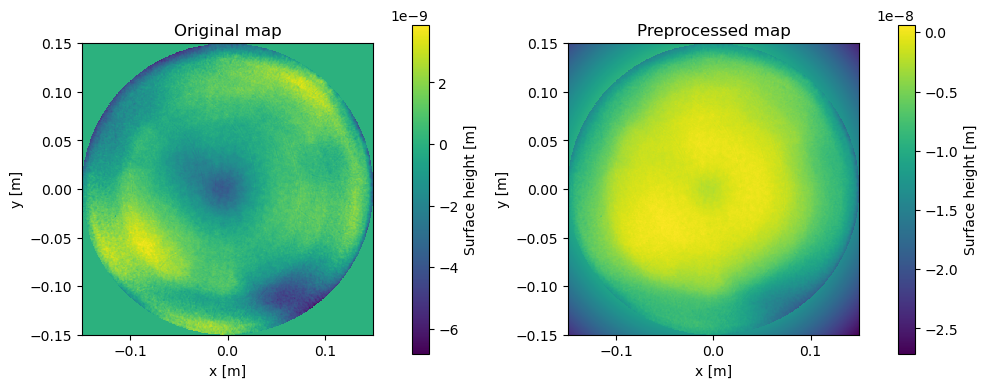

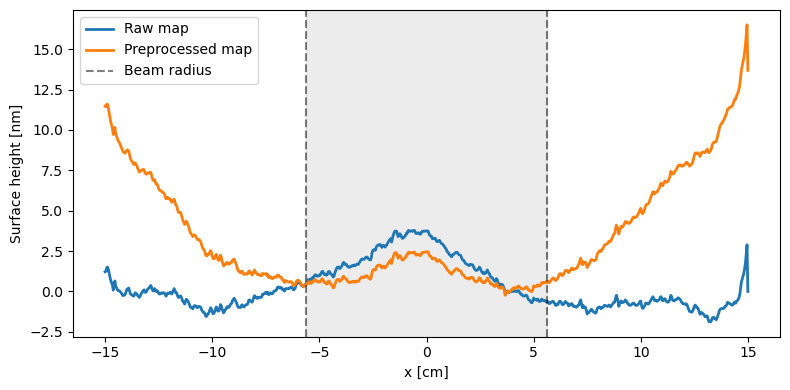

In [ ]:
# print table 
rms_before = np.nanstd(Z_nan)
rms_after  = np.nanstd(Z_prep)

print(f"{'Quantity':<15} {'Before':>12} {'After':>12}")
print("-"*45)

print(f"{'Piston [nm]':<15} {pp*1e9:12.3f} {pp2*1e9:12.3f}")
print(f"{'X tilt':<15} {yaw:12.3e} {yaw2:12.3e}")
print(f"{'Y tilt':<15} {pitch:12.3e} {pitch2:12.3e}")
print(f"{'X curv':<15} {a:12.3e} {a2:12.3e}")
print(f"{'Y curv':<15} {b:12.3e} {b2:12.3e}")
print(f"{'RMS [nm]':<15} {rms_before*1e9:12.3f} {rms_after*1e9:12.3f}")
# plot  maps side by side
fig, axs = plt.subplots(1, 2, figsize=(10,5))
_, _, cbar1 = plot_map(x_raw, y_raw, Z_nan,
                       ax=axs[0],
                       title='Original map')

_, _, cbar2 = plot_map(x_map, y_map, Z_prep,
                       ax=axs[1],
                       title='Preprocessed map')
cbar1.set_label('Surface height [m]')
cbar2.set_label('Surface height [m]')
for ax in axs:
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')

plt.tight_layout()
plt.show()
#-----------------------------------------------------------
# compare maps profile
center = len(y_map) // 2

fig, ax = plt.subplots(figsize=(8,4))

ax.plot(
    x_raw*100,
    -Z_raw[center,:]*1e9,
    lw=2,
    label='Raw map'
)

ax.plot(
    x_map*100,
    -Z_prep[center,:]*1e9,
    lw=2,
    label='Preprocessed map'
)

# beam radius
ax.axvline(
    -beam_spotsize*100,
    color='k',
    ls='--',
    alpha=0.5
)

ax.axvline(
    beam_spotsize*100,
    color='k',
    ls='--',
    alpha=0.5,
    label='Beam radius'
)

# alternatively shade the beam region
ax.axvspan(
    -beam_spotsize*100,
    beam_spotsize*100,
    color='grey',
    alpha=0.15
)

ax.set_xlabel('x [cm]')
ax.set_ylabel('Surface height [nm]')
ax.legend()

plt.tight_layout()
#plt.savefig('profiles.png')
plt.show()

# 2. How to add Mirror Maps into a triangular cavity 
To model a triangular cavity in Finesse, we use Beam Splitter (BS) components (`bs name R=none T=none L=none phi=0 alpha=0 Rc=inf xbeta=0 ybeta=0 ...`; see the [syntax](https://finesse.ifosim.org/docs/latest/usage/model_building/elements/optics/beamsplitter.html#kat-element-bs)). Since mirror maps cannot currently be applied directly to BS components, an alternative approach is required to make the optical field interact with the measured mirror surface.

To achieve this, the mirror maps are applied to dummy `lens` components placed immediately in front of the corresponding mirrors. In this configuration, the optical field acquires the phase distortions encoded in the map before being reflected by the BS, effectively reproducing the effect of a non-ideal mirror surface. The distance between each lens and the corresponding mirror is set to zero so that no additional propagation effects are introduced.


In [8]:
triang_cav =finesse.Model()

code = """
#variable
var Rcxy 184.9 

#laser
laser laser1 P=1
s s0 laser1.p1 m_in.p1 L=1

## input mirror -> output mirror
bs m_in R=0.99712 T=2880u alpha=44.99138341714505
s s_IO m_in.p3 map_out.p1 L=0.08625

# mirror map for output mirror
lens map_out f=inf
s s_mapOut_mOut map_out.p2 m_out.p1 L=0

## output mirror -> end mirror
bs m_out R=0.997146 T=2854u alpha=44.99138341714505

# external baffle near output mirror
s s_mOut_bafOut m_out.p2 baf_out.p1 L=0.065
lens baf_out f=inf
s s_bafOut_mapEnd baf_out.p2 map_end.p1 L=143.314375

# mirror map for end mirror
lens map_end f=inf
s s_mapEnd_mEnd map_end.p2 m_em.p1 L=0

## end mirror
bs m_em R=1 T=0 alpha=0.01723316570989895 Rc=[Rcxy,Rcxy]

## end mirror -> input mirror
s s_mEnd_bafIn m_em.p2 baf_in.p1 L=143.319375

# external baffle near input mirror
lens baf_in f=inf
s s_bafIn_mapIn baf_in.p2 map_in.p1 L=0.06

# mirror map for input mirror
lens map_in f=inf
s s_mapIn_mIn map_in.p2 m_in.p4 L=0

################ DETECTORS
#beam size on mirrors
bp bp_em    m_em.p1.i  w direction=x
bp bp_in    m_in.p3.o  w direction=x
bp bp_out   m_out.p1.i w direction=x

# beam size on baffles
bp bp_bafIn  baf_in.p1.i  w direction=x
bp bp_bafOut baf_out.p1.i w direction=x

# carrier amplitude detectors
ad ad_trans_00 m_out.p3.o f=laser1.f
ad ad_refl_00  m_in.p1.o  f=laser1.f
ad ad_circ_00  m_in.p4.i  f=laser1.f

# power detectors
pd pd_tran m_out.p3.o
pd pd_in   m_in.p1.i
pd pd_circ m_in.p4.i
pd pd_refl m_in.p1.o

# field detector
fd fd1 m_in.p4.i 0

modes(maxtem=5)

cav cav1 m_in.p3"""

triang_cav.parse(code)
# beam parameter for mirror-refl model + spotsize for ptr removal
triang_cav.beam_trace()
qin_trCav = triang_cav.m_em.p1.i.qx    # all beam parameters in x direction
beam_spotsize_trCav = qin_trCav.w   
print(qin_trCav) #check

BeamParam(w0=5.111 mm, z=143.42 m, w=10.791 mm, Rc=184.9 m)


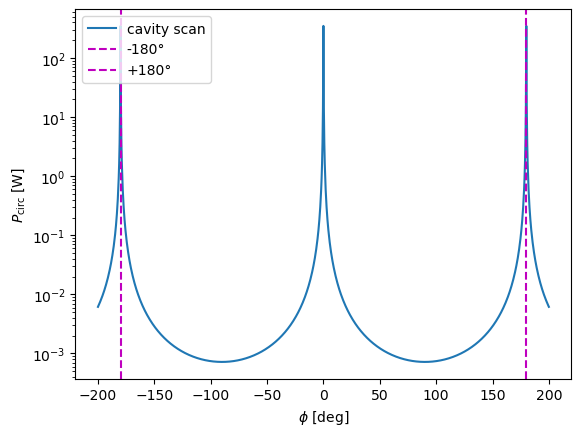

In [9]:
# check resonance 
b_fsr = triang_cav.deepcopy()

o_fsr = b_fsr.run('xaxis(m_em.phi,lin,-200,200,1000)') 

# plot     
fig, ax = plt.subplots()

ax.plot(o_fsr.x1, o_fsr['pd_circ'], label='cavity scan')

ax.axvline(o_fsr.x1[50], color='m', linestyle='--', label='-180°')
ax.axvline(o_fsr.x1[950], color='m', linestyle='--', label='+180°')

ax.set_yscale('log')

ax.set_xlabel(r'$\phi$ [deg]')
ax.set_ylabel(r'$P_{\rm circ}$ [W]')

ax.legend(loc='upper left')

### Prepare mirror maps as surface objects in Finesse3

In [10]:
# utilities function to preprocess and display removed coefficients
def preprocess_map(x_raw, y_raw, Z_raw, beam_spotsize, print_info=False):
    """
    Preprocess a mirror map:
      - remove NaNs
      - compute maximum circular aperture radius
      - remove piston, tilt and curvature (Finesse HG method)

    Parameters
    ----------
    x_raw, y_raw : ndarray
        Map coordinates.
    Z_raw : ndarray
        Raw map data.
    beam_spotsize : float
        Beam radius used for HG-weighted preprocessing.
    print_intrfo : bool, optional
        Print preprocessing summary.

    Returns
    -------
    x_map, y_map : ndarray
        Coordinates.
    Z_prep : ndarray
        Preprocessed map.
    Rmax : float
        Maximum inscribed circular radius.
    coeffs : dict
        Removed coefficients.
    """

    # maximum inscribed circular aperture
    max_x = min(-x_raw[0], x_raw[-1])
    max_y = min(-y_raw[0], y_raw[-1])
    Rmax = min(max_x, max_y)

    # remove NaNs
    Z_nan = remove_NaN(Z_raw.copy())

    # remove piston, tilt and curvature
    x_map, y_map, Z_prep, pp, yaw, pitch, a, b = remove_tpr_finesse(
        x_raw,
        y_raw,
        Z_nan,
        beam_spotsize,
        piston=True,
        tilt=True,
        roc=True
    )

    coeffs = {
        "piston": pp,
        "yaw": yaw,
        "pitch": pitch,
        "curvature_x": a,
        "curvature_y": b,
    }

    if print_info:

        rms_before = np.nanstd(Z_nan)
        rms_after = np.nanstd(Z_prep)

        print("\nMirror map preprocessing summary")
        print("-" * 55)
        print(f"Rmax            : {Rmax:.4f} m")
        print(f"Beam radius     : {beam_spotsize:.4f} m")
        print(f"NaNs removed    : {np.isnan(Z_raw).sum()}")
        print()
        print(f"{'Quantity':<18} {'Value':>15}")
        print("-" * 35)
        print(f"{'Piston [nm]':<18} {pp*1e9:15.3f}")
        print(f"{'Yaw tilt':<18} {yaw:15.3e}")
        print(f"{'Pitch tilt':<18} {pitch:15.3e}")
        print(f"{'X curvature':<18} {a:15.3e}")
        print(f"{'Y curvature':<18} {b:15.3e}")
        print(f"{'RMS before [nm]':<18} {rms_before*1e9:15.3f}")
        print(f"{'RMS after [nm]':<18} {rms_after*1e9:15.3f}")

    return x_map, y_map, Z_prep, Rmax, coeffs

In [11]:
# load the .dat files that contain the maps 
# input/output
x1r,y1r,map_in_r = load_metropro('mirror_maps_files/c14065_10_subA_50mm.dat')
x2r,y2r,map_out_r= load_metropro('mirror_maps_files/c14065_20_subB_50mm.dat')
# curved mirror
x3r,y3r,map_end_r = load_metropro('mirror_maps_files/16628_C1904311final130mmcorrigFINAL.dat')

In [12]:
# PREPROCESS THE MAPS BEFORE TO MAKE THE FINESSE MIRROR SURFACE :-)
x1, y1, map_in, Rmax_in, coeffs_in = preprocess_map(
    x1r,
    y1r,
    map_in_r,
    beam_spotsize_trCav,
    print_info=True
)
x2, y2, map_out, Rmax_out, coeffs_out = preprocess_map(
    x2r,
    y2r,
    map_out_r,
    beam_spotsize_trCav,
    print_info=True
)
x3, y3, map_end, Rmax_end, coeffs_end = preprocess_map(
    x3r,
    y3r,
    map_end_r,
    beam_spotsize_trCav,
    print_info=True
)


Mirror map preprocessing summary
-------------------------------------------------------
Rmax            : 0.0250 m
Beam radius     : 0.0108 m
NaNs removed    : 3768

Quantity                     Value
-----------------------------------
Piston [nm]                 -0.190
Yaw tilt                -3.681e-08
Pitch tilt              -5.429e-09
X curvature              6.275e-06
Y curvature             -1.208e-06
RMS before [nm]              1.232
RMS after [nm]               1.431

Mirror map preprocessing summary
-------------------------------------------------------
Rmax            : 0.0250 m
Beam radius     : 0.0108 m
NaNs removed    : 3764

Quantity                     Value
-----------------------------------
Piston [nm]                 -7.037
Yaw tilt                -1.499e-08
Pitch tilt              -3.264e-09
X curvature              3.064e-05
Y curvature              2.349e-05
RMS before [nm]              4.760
RMS after [nm]               5.927

Mirror map preprocessing summar

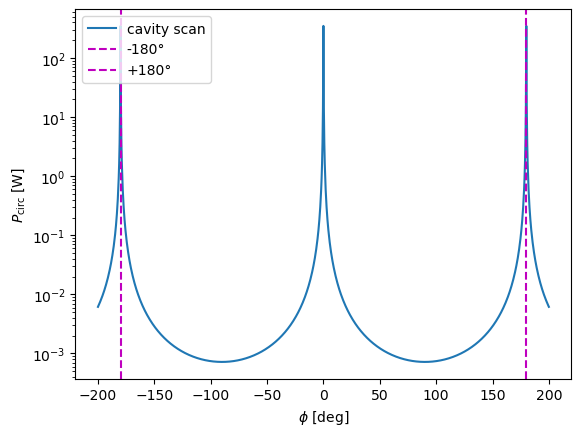

In [13]:
# prepare the maps as surf objects in finesse
surf_in = fmaps.Map(x1,y1,
                  opd=map_in
                  )
surf_out = fmaps.Map(x2,y2,
                  opd=map_out
                  )
surf_end = fmaps.Map(x3,y3,
                  opd=map_end
                  )

# add mirror maps in the model
triang_cav.map_in.OPD_map = surf_in
triang_cav.map_out.OPD_map = surf_out
triang_cav.map_end.OPD_map = surf_end

out_maps = triang_cav.run()

o_fsr1 = b_fsr.run('xaxis(m_em.phi,lin,-200,200,1000)') 

# plot to check that we dind't lose resonance condition
fig, ax = plt.subplots()

ax.plot(o_fsr1.x1, o_fsr1['pd_circ'], label='cavity scan')

ax.axvline(o_fsr1.x1[50], color='m', linestyle='--', label='-180°')
ax.axvline(o_fsr1.x1[950], color='m', linestyle='--', label='+180°')

ax.set_yscale('log')

ax.set_xlabel(r'$\phi$ [deg]')
ax.set_ylabel(r'$P_{\rm circ}$ [W]')

ax.legend(loc='upper left')

# 3. What if the baffles are not mounted on the mirrors?

Baffles can be modeled in Finesse using lenses with amplitude apertures applied to them. This approach is straightforward when the baffle is mounted directly on a mirror, since the aperture can be applied to the same lens used to host the mirror phase map.

In some optical layouts, however, such as triangular cavities with dihedral input and end mirrors, the baffles are located at a significant distance from the mirror surfaces. In these cases, it is not sufficient to place a simple circular aperture in the beam path. The aperture must also reproduce the physical orientation of the baffle with respect to the incident beam.

Including the correct inclination ensures that the beam interacts with the aperture under the same geometric conditions as in the real system. As a result, the mirrors "see" the projected shape of the baffle exactly as they would in the experiment, leading to a more realistic estimate of clipping losses and scattered-light interception. From the beam perspective, the projected aperture is no longer perfectly circular but appears elliptical.

As an example, consider a baffle tilted by (5^\circ) with respect to the mirror (x)-axis. This geometry can be reproduced in Finesse by defining a flat map object containing an inclined circular aperture. Since Finesse expects angles in radians, the tilt angle must first be converted from degrees. The projected aperture can then be generated as

`surf = fmaps.Map(x,y,amplitude=fmutil.circular_aperture(x * np.cos(0.0872665),y,aperture_radius))`

where $0.0872665rad$ corresponds to $5^\circ$. No OPD data are provided, so the map acts as a purely amplitude-clipping element and does not introduce any additional phase distortion to the optical field.

![image info](mirror_maps_files/baffle_model.png)

In [14]:
# adding baffles into our simulation
triang_cav1 = triang_cav.deepcopy()
baff_in = fmaps.Map(x1,y1,
                  #opd=map_opd,   if I don't give an opd F3 considers the map as flat
                     # the baffles are tilted of 5°
                  amplitude=fmutil.circular_aperture(x1*np.cos(0.0872665),y1, 0.025), #50mm diameter
                 )
baff_out = fmaps.Map(x2,y2,
                  #opd=map_opd,   if I don't give an opd F3 considers the map as flat
                     # the baffles are tilted of 5°
                  amplitude=fmutil.circular_aperture(x2*np.cos(0.0872665),y2,0.025),
                 )

triang_cav1.baf_in.OPD_map = baff_in
triang_cav1.baf_out.OPD_map = baff_out
out_baf1 = triang_cav1.run()
out_baffles = triang_cav1.run('xaxis(m_em.phi,lin,-200,200,1000)')

/var/folders/y4/lgs0ldbd687dblg61w7yxtk80000gn/T/ipykernel_87287/3699003263.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


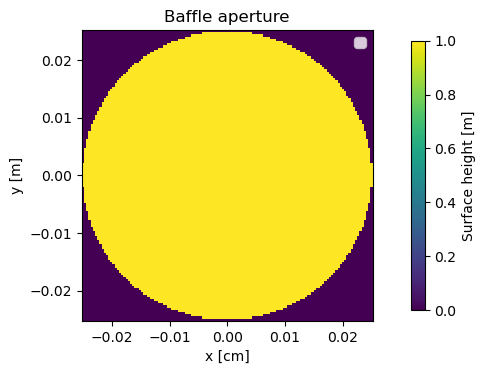

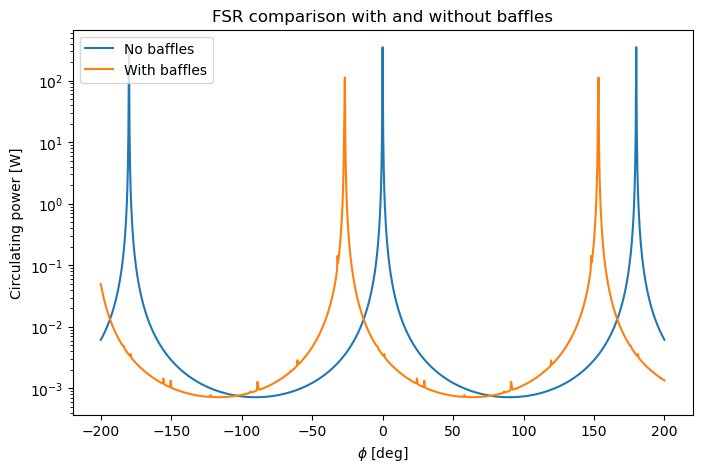

In [15]:
# checking that the apertures on the baffle is elliptical shape
_,ax,cbar = plot_map(
    baff_in.x,
    baff_in.y,
    baff_in.amplitude,
    title='Baffle aperture'
)
cbar.set_label('Surface height [m]')
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [m]')
ax.legend()
# fsr comparison with and without baffles
fig, ax = plt.subplots(figsize=(8,5))

ax.plot(
    o_fsr.x1,
    o_fsr['pd_circ'],
    label='No baffles'
)
ax.set_yscale('log')
ax.plot(
    out_baffles.x1,
    out_baffles['pd_circ'],
    label='With baffles'
)
ax.set_title('FSR comparison with and without baffles')
ax.set_xlabel(r'$\phi$ [deg]')
ax.set_ylabel('Circulating power [W]')
ax.legend()

# 4. Higher Order Modes content in a cavity

It is often useful to investigate the higher-order mode (HOM) content generated within an optical model. In Finesse, this can be done using a field detector (`fd`), which records the complex amplitudes of all Hermite--Gaussian modes present at a given location in the optical system.

When a simulation is run for a single operating point, the field detector returns the modal amplitudes corresponding to that specific cavity configuration. More commonly, however, simulations involve scanning a parameter, such as a mirror phase, cavity length, or mirror curvature. In this case, the field detector records the modal amplitudes at every step of the scan, producing a complete description of how the HOM content evolves as the chosen parameter is varied.

The resulting data can be used to identify which modes are excited by optical imperfections, evaluate mode coupling, and quantify the impact of mirror surface errors, clipping, or misalignments on the cavity performance.


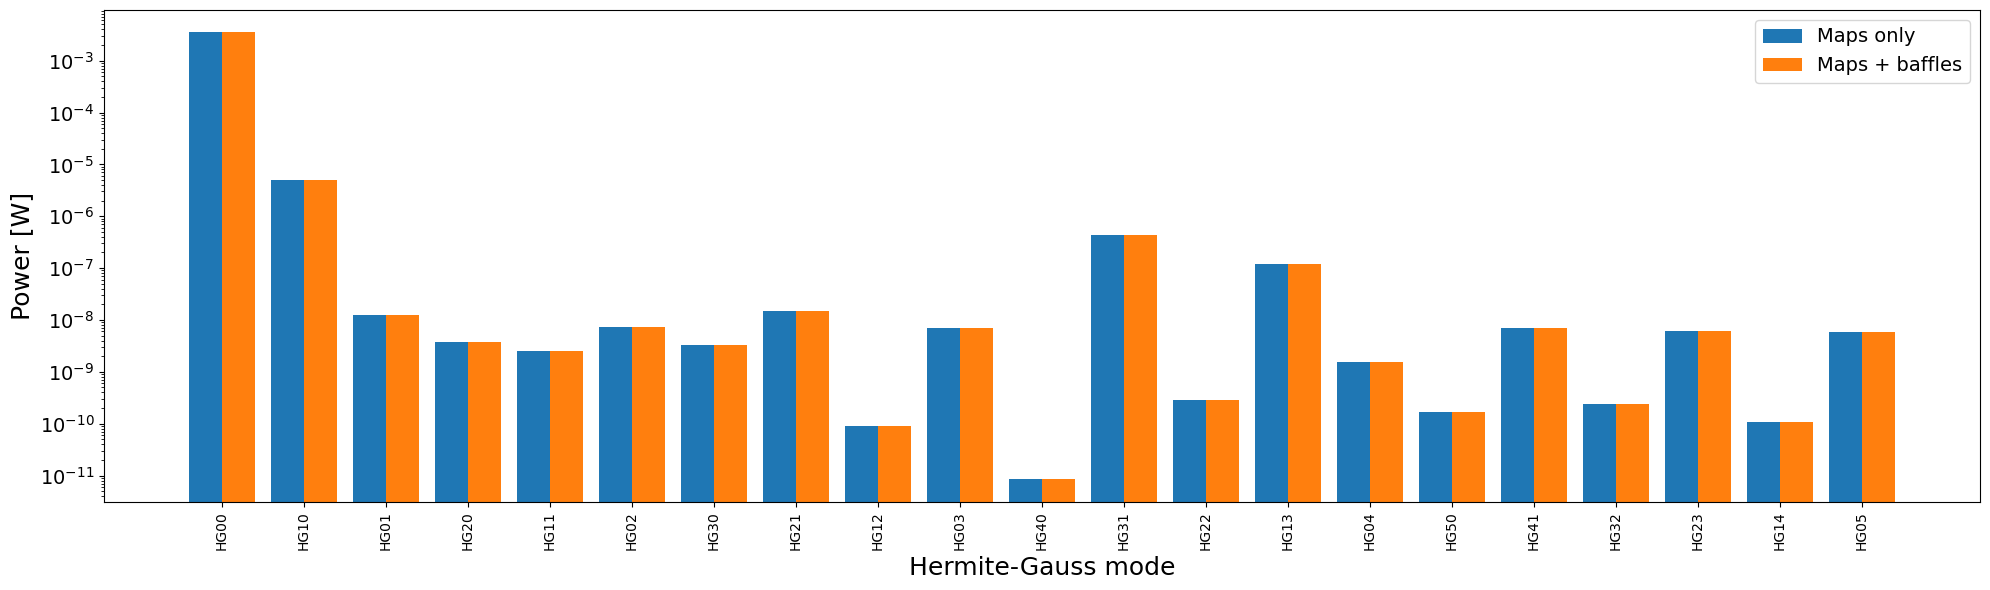

In [16]:
# HOM powers
P0 = np.abs(out_maps['fd1'])**2
P1 = np.abs(out_baf1['fd1'])**2

labels = [f'HG{n}{m}' for n, m in triang_cav.homs]

x = np.arange(len(labels))
width = 0.4

fig, ax = plt.subplots(figsize=(20,6))

ax.bar(
    x - width/2,
    P0,
    width,
    label='Maps only'
)

ax.bar(
    x + width/2,
    P1,
    width,
    label='Maps + baffles'
)

ax.set_yscale('log')

ax.set_xlabel('Hermite-Gauss mode', fontsize=18)
ax.set_ylabel('Power [W]', fontsize=18)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=10)

ax.tick_params(axis='y', labelsize=14)

ax.legend(fontsize=14)

plt.tight_layout()
plt.show()